# Elliptical Trajectory Conditions (Smaller Scale) and CNN Inference

We reduced ellipse perimeter from 160 cm to **32 cm**, retained the **2.5 s period**, and kept the same relative velocity modulation and slowing locations. Average speed is therefore 12.8 cm/s. This is a scaled exploratory test of the idea, not an exact replication of the human experiment.

Sources: Viviani, Baud-Bovy & Redolfi (1997), Experiment 1, Table 1 and Figure 3, [primary paper](../../Elliptical%20Trajectories/Perceiving_and_Tracking_Kinesthetic_Stimuli_Furthe%20(1).pdf). Published pretrained weights: [Zenodo 15111808](https://zenodo.org/records/15111808). The older full-size ensemble notebook is archived under `notebooks/archive/` and is not run here.


**Aligned protocol update:** shoulder-height placement, participant-left starting point, and counterclockwise movement. The single `0_9` checkpoint is used again. Human uncertainty and model reconstruction-error bars are defined explicitly in Sections 4–5.


## 1. Elliptical trajectories being tested

Positive signed eccentricity means a horizontal ellipse; negative means vertical. Seven shapes × three velocity conditions give **21 trajectories**. A has constant tangential speed. B slows at the left/right extremes. C slows at the top/bottom. Spatial scaling changes absolute speeds but preserves the phase and the relative speed pattern exactly; this invariant is checked in the tests.

Paths are now centered at right-shoulder height in a frontoparallel plane 45 cm anterior to the model's torso reference origin. That torso origin approximates the study's chest reference because the model has no chest-surface marker. Each trajectory starts at the participant's leftmost point and initially moves downward: counterclockwise from their view. The circle radius is 5.09 cm; the most elongated ellipse has semiaxes about 7.54 and 2.35 cm. Three cycles are generated; shape readout uses the final cycle.

The reference Lissajous eccentricity remains .9, giving a speed ratio 2.294. The paper's stated numerical ratio 3.205 corresponds to .95; changing that parameter is a separate sensitivity test.

**Axes:** model ground Z points toward the right arm, while the pipeline uses X = −ground Z. All horizontal plots below therefore use participant-right = −pipeline X, and vertical = pipeline Z. The earlier plots were mirrored horizontally. Starting at full prescribed speed is retained; the paper's half-cycle acceleration ramp and self-paced stopping are not reproduced.


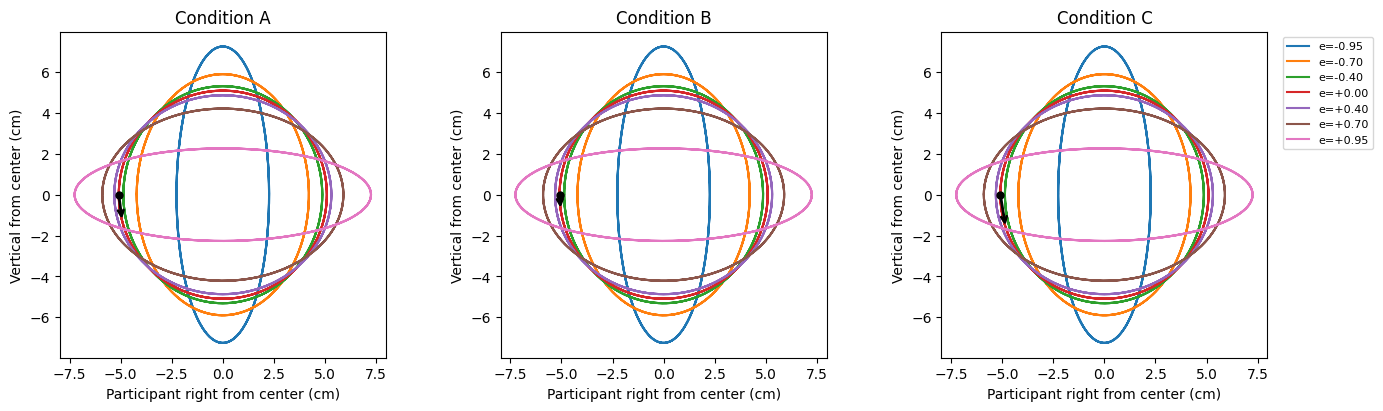

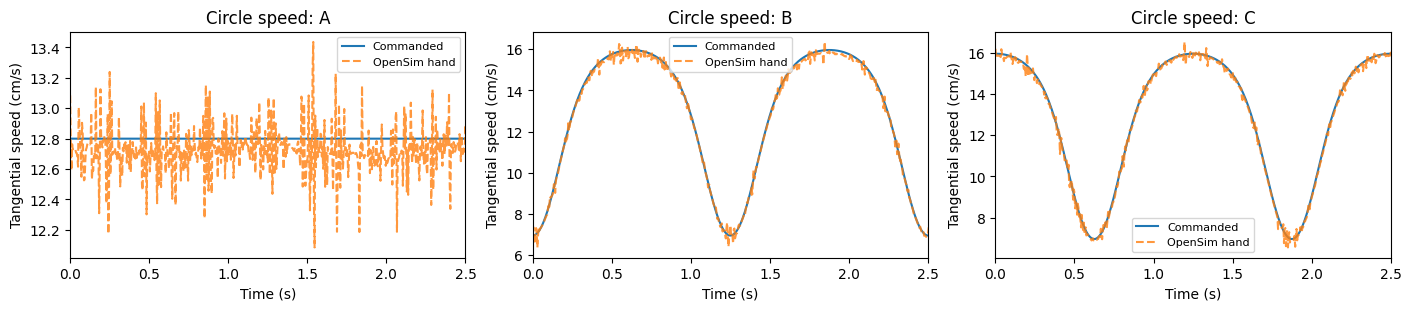

In [1]:
from pathlib import Path
import os, sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'run_pipeline.py').exists())
CONFIG_PATH=ROOT/'experiments/viviani_aligned.yaml'
CONFIG=yaml.safe_load(CONFIG_PATH.read_text())
OUT=ROOT/'outputs'/CONFIG['experiment'];OUT.mkdir(exist_ok=True)
OPEN_SIM_PYTHON=ROOT/'.venv-opensim/bin/python'
INFERENCE_PYTHON=ROOT/'.venv-mujoco/bin/python'
CHECKPOINT=ROOT/CONFIG['proprioception']['model_path']
RUN_BIOMECHANICS=False  # True reruns the original path → IK → motion → muscle → spindle stages.
RUN_INFERENCE=False  # True reruns the original inference stage, with just the configured CNN.
CIRCLE_RATIO_TOLERANCE=1.05
CLASSES=['true circle','horizontal ellipse','vertical ellipse']
PERIOD=CONFIG['path']['ellipse']['period_s'];FS=CONFIG['path']['sample_rate_hz']
plt.rcParams.update({'font.size':10,'figure.figsize':(10,4)})
def participant_xz(xyz):
    return np.asarray(xyz)[:,[0,2]]*np.array([-1.,1.])

CONFIG_SIGNATURE=hashlib.sha256(json.dumps(CONFIG,sort_keys=True).encode()).hexdigest()

def run_stage(stage,python):
    (OUT/'.matplotlib').mkdir(exist_ok=True)
    command=[str(python),'-c',f"from run_pipeline import Pipeline; Pipeline({str(CONFIG_PATH)!r}).run_stage({stage!r})"]
    env=dict(os.environ,MPLBACKEND='Agg',MPLCONFIGDIR=str(OUT/'.matplotlib'))
    log=OUT/(stage+'.log')
    with log.open('w') as stream:
        result=subprocess.run(command,cwd=ROOT,env=env,stdout=stream,stderr=subprocess.STDOUT)
    if result.returncode:raise RuntimeError(f'{stage} failed: {log}\n'+log.read_text()[-2000:])
    print('Completed',stage)

if RUN_BIOMECHANICS:
    for stage in ['path','inverse-kinematics','motion','muscle-lengths','muscle-signals']:run_stage(stage,OPEN_SIM_PYTHON)
stimuli=pd.read_csv(OUT/'stimuli.csv')
manifest=yaml.safe_load((OUT/'manifest.yaml').read_text());entries={r['id']:r for r in manifest['trajectories']}
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for ax,condition in zip(axes,'ABC'):
    for row in stimuli[stimuli.condition==condition].itertuples():
        d=np.load(OUT/entries[row.id]['desired_path']);center=d['center_xyz'];xy=participant_xz(d['xyz']-center)
        ax.plot(*xy.T,label=f'e={row.e:+.2f}')
        if row.e==0:
            ax.scatter(*xy[0],c='black',s=25,zorder=5)
            ax.annotate('',xy=xy[25],xytext=xy[0],arrowprops=dict(arrowstyle='->',color='black',lw=2))
    ax.set(title=f'Condition {condition}',xlabel='Participant right from center (cm)',ylabel='Vertical from center (cm)',aspect='equal')
axes[-1].legend(fontsize=8,bbox_to_anchor=(1.03,1));plt.show()
fig,axes=plt.subplots(1,3,figsize=(14,3),layout='constrained')
for ax,condition in zip(axes,'ABC'):
    ident=stimuli[(stimuli.condition==condition)&(stimuli.e==0)].id.iloc[0]
    d=np.load(OUT/entries[ident]['desired_path']);speed=np.linalg.norm(np.gradient(d['xyz'],1/FS,axis=0),axis=1)
    ax.plot(d['times'],speed,label='Commanded')
    physical=np.load(OUT/entries[ident]['muscle_data'])
    delivered_speed=np.linalg.norm(np.gradient(physical['wrist_xyz_reference_world'],1/FS,axis=0),axis=1)
    ax.plot(physical['times'],delivered_speed,'--',label='OpenSim hand',alpha=.8)
    ax.set(xlim=(0,PERIOD),title=f'Circle speed: {condition}',xlabel='Time (s)',ylabel='Tangential speed (cm/s)');ax.legend(fontsize=8)
plt.show()


## 2. Check muscle paths, then calculate spindle firing rates

**Original-pipeline test:** a 32 cm circle at the original rest posture produced fibres around 19–208 mm, without the earlier metre-scale failures. This baseline is retained in `outputs/viviani_small_probe/`.

**First failed large-path sample:** `A_m0_40`, frame 0, teres minor (`TMIN`). Shoulder elevation was about 139.2°. Its saved fibre length was 2,217 mm; a fresh OpenSim model reproduced that value. The full muscle–tendon path was 2,631 mm. Inspection of `GeometryPath.getCurrentPath()` showed generated wrapping points far outside the shoulder region. This confirms a failed muscle route at that posture; it does not justify changing a wrapping surface globally.

**Correction:** use smaller paths in the aligned shoulder-height plane and align forearm rotation between IK and muscle extraction. The original IK brace was −30° while the training-compatible extractor used the model's 0° default. Both now use 0°, preserving the original four-coordinate muscle-input convention. The original OpenSim IK backend is retained; the original .001 posture regularization is retained to keep muscle signals smooth. No wrapping surfaces were disabled and no fibre lengths were clipped or replaced.

The graphs below inspect the failed and successful muscle routes and verify all 21 new conditions. These checks screen for simulation failures; they are not a full physiological validation. The spindle calculation is the existing 25-muscle, 5 Ia + 5 II pipeline with coefficient seed 0.

The hand-tracking screen is 0.2 cm (2 mm); delivered shape labels are also checked against commanded labels. A trial with reduced posture regularization improved marker error but caused joint/velocity jumps, so that setting was rejected before final inference.

The 3D diagnostic connects the path points returned by OpenSim; it does not render the curved wrapping arcs. Reported muscle–tendon lengths come directly from OpenSim.

**Posture reference at the new height:** a pilot circle supplied a nearer IK reference for elevation, elevation angle and elbow flexion; shoulder rotation retains the original 25° reference. This changes the simulation posture, not the CNN weights. Every final condition is screened again for path error, fibre length and fibre velocity before inference.


,id,max_hand_error_cm,min_fiber_mm,max_fiber_mm,min_normalized_length,max_normalized_length,peak_velocity_mm_s,min_rate_hz,max_rate_hz,delivered_class,delivered_ratio,passed
0,A_m0_95,0.074868,17.319443,233.847458,0.638855,1.422756,247.613510,0.0,32.145386,vertical ellipse,0.311157,True
1,B_m0_95,0.074836,17.320299,233.854675,0.638861,1.422752,245.641464,0.0,32.102406,vertical ellipse,0.311213,True
2,C_m0_95,0.075606,17.319784,233.849670,0.638010,1.422763,244.971298,0.0,31.563774,vertical ellipse,0.311128,True
3,A_m0_70,0.072091,17.461544,232.716354,0.634540,1.423171,253.278793,0.0,31.416918,vertical ellipse,0.711045,True
4,B_m0_70,0.074896,17.462477,232.604630,0.634506,1.423175,238.914169,0.0,30.956509,vertical ellipse,0.711081,True
5,C_m0_70,0.074869,17.461010,232.729156,0.634533,1.423188,237.156357,0.0,30.453293,vertical ellipse,0.711060,True
6,A_m0_40,0.077095,17.516512,232.193115,0.632479,1.423296,234.871201,0.0,30.347000,vertical ellipse,0.912516,True
7,B_m0_40,0.077671,17.516804,232.180237,0.633023,1.423386,235.360092,0.0,30.480856,vertical ellipse,0.912653,True
8,C_m0_40,0.075748,17.516285,232.204269,0.633003,1.423299,233.979477,0.0,30.064438,vertical ellipse,0.912371,True
9,A_p0_00,0.078776,17.536245,232.007004,0.632851,1.423340,233.505234,0.0,30.180302,true circle,0.995850,True


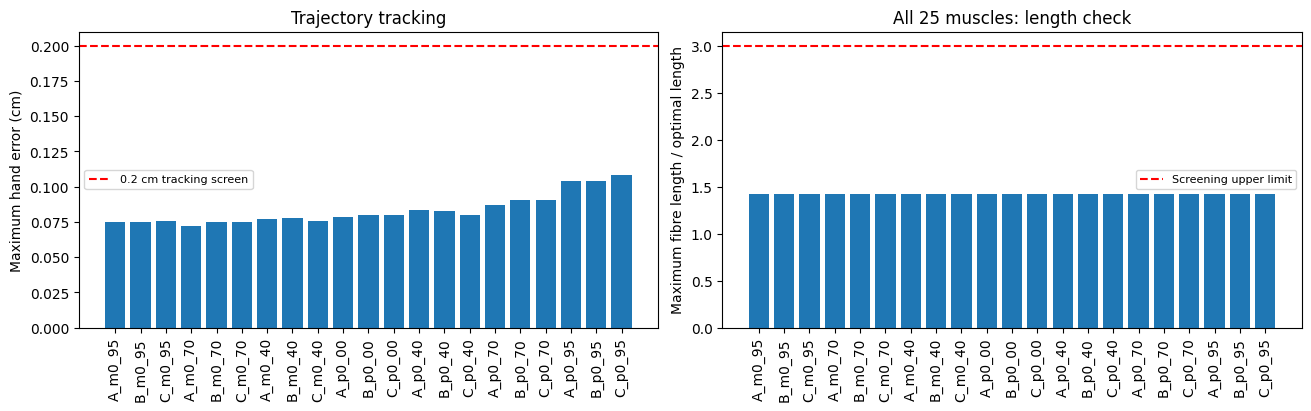

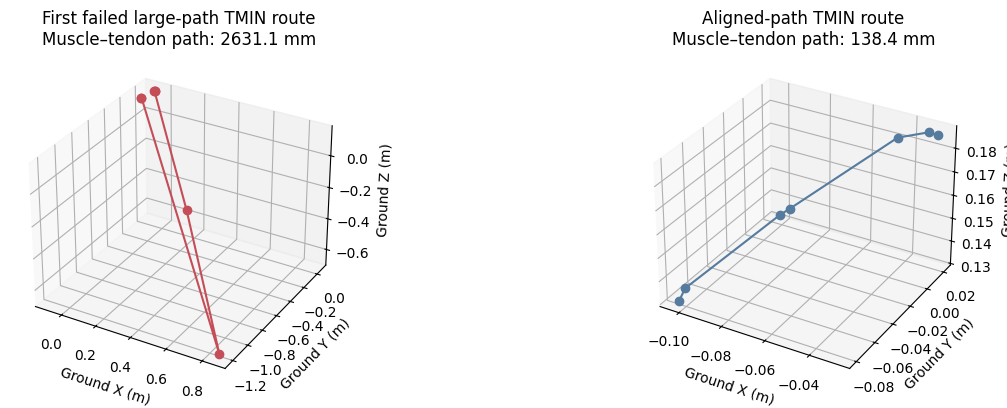

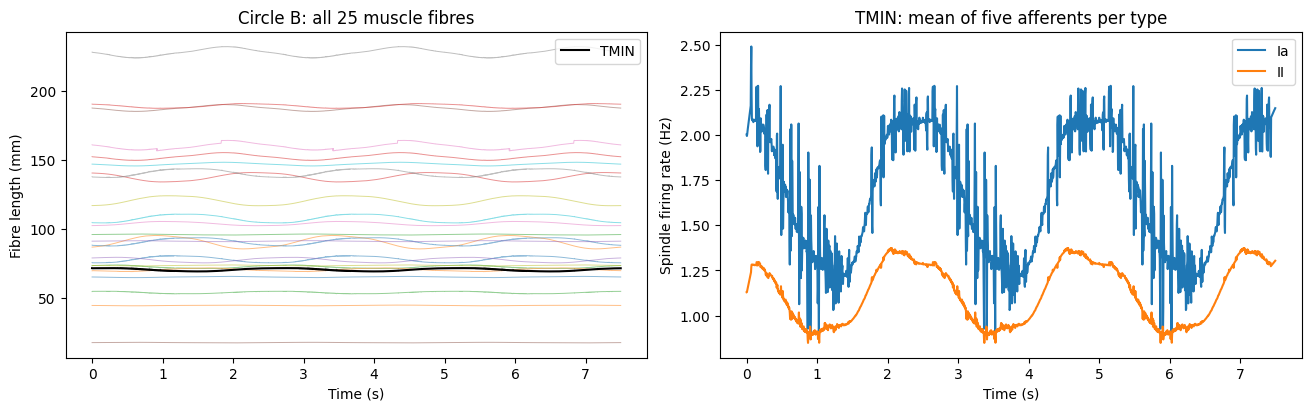

All 21 stimuli pass the simulation checks.


In [2]:
optimal=np.asarray(yaml.safe_load((ROOT/'extract_data/configs/train_test_data_spindles_extended.yaml').read_text())['optimal_lengths'])
quality=[]
for row in stimuli.itertuples():
    item=entries[row.id];desired=np.load(OUT/item['desired_path']);muscle=np.load(OUT/item['muscle_data']);spindle=np.load(OUT/item['spindle_data'])
    lengths=muscle['fiber_lengths'];ratio=lengths/optimal[None,:]
    error=np.linalg.norm(muscle['wrist_xyz_reference_world']-desired['xyz'],axis=1)
    extent=np.ptp(muscle['wrist_xyz_reference_world'][-600:,[0,2]],axis=0)
    delivered_ratio=extent[0]/extent[1]
    delivered_class=CLASSES[0] if 1/CIRCLE_RATIO_TOLERANCE<=delivered_ratio<=CIRCLE_RATIO_TOLERANCE else CLASSES[1 if delivered_ratio>1 else 2]
    peak_velocity=np.abs(np.gradient(lengths,1/FS,axis=0)).max()
    rates=spindle['firing_rates']
    passed=bool(np.isfinite(lengths).all() and np.isfinite(rates).all() and ratio.min()>.1 and ratio.max()<3 and error.max()<.2 and peak_velocity<500 and delivered_class==row.correct)
    quality.append(dict(id=row.id,max_hand_error_cm=error.max(),min_fiber_mm=lengths.min(),max_fiber_mm=lengths.max(),min_normalized_length=ratio.min(),max_normalized_length=ratio.max(),peak_velocity_mm_s=peak_velocity,min_rate_hz=rates.min(),max_rate_hz=rates.max(),delivered_class=delivered_class,delivered_ratio=delivered_ratio,passed=passed))
quality=pd.DataFrame(quality);quality.to_csv(OUT/'quality.csv',index=False)
display(quality)
assert quality.passed.all(), 'A simulation check failed; inspect the inputs before running the CNN.'
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axes[0].bar(quality.id,quality.max_hand_error_cm);axes[0].axhline(.2,c='red',ls='--',label='0.2 cm tracking screen');axes[0].tick_params(axis='x',rotation=90);axes[0].set(ylabel='Maximum hand error (cm)',title='Trajectory tracking');axes[0].legend(fontsize=8)
axes[1].bar(quality.id,quality.max_normalized_length);axes[1].axhline(3,c='red',ls='--',label='Screening upper limit');axes[1].tick_params(axis='x',rotation=90);axes[1].set(ylabel='Maximum fibre length / optimal length',title='All 25 muscles: length check');axes[1].legend(fontsize=8);plt.show()
audit=json.loads((OUT/'muscle_path_audit.json').read_text())
fig=plt.figure(figsize=(13,4.5));fig.subplots_adjust(left=.03,right=.88,bottom=.10,top=.85,wspace=.30)
for index,key,title in [(1,'failed','First failed large-path TMIN route'),(2,'small','Aligned-path TMIN route')]:
    ax=fig.add_subplot(1,2,index,projection='3d');a=audit[key];xyz=np.array(a['path_points_ground_m'])
    ax.plot(*xyz.T,'o-',color='#c44d58' if key=='failed' else '#557b9e')
    ax.set(title=f"{title}\nMuscle–tendon path: {a['musculotendon_length_mm']:.1f} mm",xlabel='Ground X (m)',ylabel='Ground Y (m)',zlabel='Ground Z (m)')
plt.show()
ident=stimuli[(stimuli.condition=='B')&(stimuli.e==0)].id.iloc[0]
m=np.load(OUT/entries[ident]['muscle_data']);s=np.load(OUT/entries[ident]['spindle_data'])
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axes[0].plot(m['times'],m['fiber_lengths'],alpha=.5,lw=.7)
i=list(m['muscle_names']).index('TMIN');axes[0].plot(m['times'],m['fiber_lengths'][:,i],c='black',lw=1.5,label='TMIN')
axes[0].set(xlabel='Time (s)',ylabel='Fibre length (mm)',title='Circle B: all 25 muscle fibres');axes[0].legend()
for start,label in [(0,'Ia'),(5,'II')]:
    axes[1].plot(s['times'],s['firing_rates'][0,start:start+5,i,:].mean(axis=0),label=label)
axes[1].set(xlabel='Time (s)',ylabel='Spindle firing rate (Hz)',title='TMIN: mean of five afferents per type');axes[1].legend();plt.show()
print('All',len(quality),'stimuli pass the simulation checks.')


## 3. Single-CNN reconstruction and shape classification

This runs `process/centeroutinference.py`, the inference stage already used in your codebase, with the configured `0_9` checkpoint. Its existing normalization and `replicate` temporal padding are preserved. The original 240 Hz timebase is retained. No other checkpoint is loaded.

The CNN outputs wrist XYZ and four joint angles. To read shape in the physical frontoparallel plane, its four predicted joint angles are placed in the same OpenSim model. Shape is measured from horizontal/vertical extent in the final cycle: a ratio within [1/1.05, 1.05] is labelled circle, greater is horizontal, smaller is vertical. This is a fixed geometric readout of the pretrained reconstruction, not a newly trained classification head or calibrated probability.


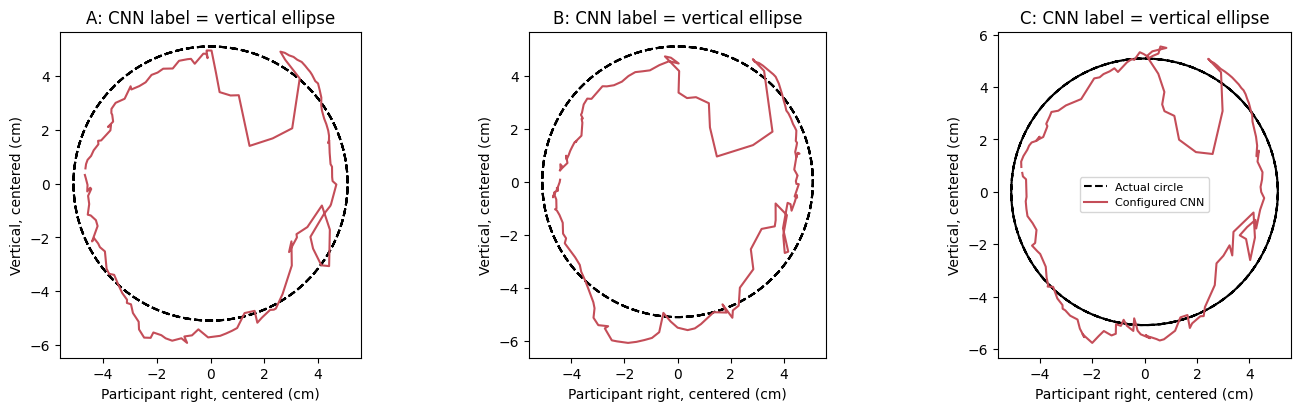

,id,correct,predicted,ratio,predicted_e,joint_out_of_bounds_fraction
0,A_m0_95,vertical ellipse,vertical ellipse,0.309867,-0.950780,0.0
1,B_m0_95,vertical ellipse,vertical ellipse,0.306586,-0.951843,0.0
2,C_m0_95,vertical ellipse,vertical ellipse,0.310188,-0.950675,0.0
3,A_m0_70,vertical ellipse,vertical ellipse,0.652628,-0.757678,0.0
4,B_m0_70,vertical ellipse,vertical ellipse,0.640562,-0.767906,0.0
5,C_m0_70,vertical ellipse,vertical ellipse,0.614375,-0.789014,0.0
6,A_m0_40,vertical ellipse,vertical ellipse,0.770818,-0.637055,0.0
7,B_m0_40,vertical ellipse,vertical ellipse,0.836986,-0.547224,0.0
8,C_m0_40,vertical ellipse,vertical ellipse,0.776949,-0.629563,0.0
9,A_p0_00,true circle,vertical ellipse,0.859863,-0.510525,0.0


Checkpoint: trained_models/experiment_causal_flag-pcr_optimized_linear_extended_5_5_letter_reconstruction_joints/spatiotemporal_4_8-8-32-64_7171_0_9
Models used: 1 | predictions: 21
Fraction of decoded frames outside joint limits: 0.0


PSE refinement: 15 additional trajectories; the same single checkpoint throughout.


In [3]:
if RUN_INFERENCE:
    run_stage('inference',INFERENCE_PYTHON)
    inventory=[]
    for row in stimuli.itertuples():
        item=yaml.safe_load((OUT/'manifest.yaml').read_text())
        entry=next(r for r in item['trajectories'] if r['id']==row.id)
        inventory.append(dict(id=row.id,condition=row.condition,e=row.e,coefficient_seed=CONFIG['proprioception']['coefficient_seed'],training_seed=CONFIG['proprioception']['training_seed'],predictions=entry['raw_predictions']))
    (OUT/'batch').mkdir(exist_ok=True)
    pd.DataFrame(inventory).to_csv(OUT/'batch/inventory.csv',index=False)
    (OUT/'generation.json').write_text(json.dumps(dict(signature=CONFIG_SIGNATURE)))
    with (OUT/'readout.log').open('w') as log:
        subprocess.run([str(OPEN_SIM_PYTHON),'process/ellipse_readout.py','--output',str(OUT),'--tolerance',str(CIRCLE_RATIO_TOLERANCE)],cwd=ROOT,stdout=log,stderr=subprocess.STDOUT,check=True)
    provenance=dict(n_models=1,model_path=str(CHECKPOINT.relative_to(ROOT)),checkpoint_sha256=hashlib.sha256((CHECKPOINT/'model.ckpt').read_bytes()).hexdigest(),config_signature=CONFIG_SIGNATURE,temporal_padding=CONFIG['proprioception']['temporal_padding_mode'])
    (OUT/'single_model_provenance.json').write_text(json.dumps(provenance,indent=2))
provenance=json.loads((OUT/'single_model_provenance.json').read_text())
assert provenance['n_models']==1 and provenance['config_signature']==CONFIG_SIGNATURE
assert provenance['checkpoint_sha256']==hashlib.sha256((CHECKPOINT/'model.ckpt').read_bytes()).hexdigest()
assert json.loads((OUT/'batch/readout.json').read_text())['tolerance']==CIRCLE_RATIO_TOLERANCE
predictions=pd.read_csv(OUT/'batch/shape_predictions.csv')
assert len(predictions)==len(stimuli) and len(predictions[['coefficient_seed','training_seed']].drop_duplicates())==1
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for ax,condition in zip(axes,'ABC'):
    row=predictions[(predictions.condition==condition)&(predictions.e==0)].iloc[0]
    xyz=np.load(OUT/row.physical_prediction)['xyz'];xy=participant_xz(xyz);xy-=xy.mean(axis=0)
    desired=np.load(OUT/entries[row.id]['desired_path']);truth=participant_xz(desired['xyz']-desired['center_xyz'])
    ax.plot(*truth.T,'k--',label='Actual circle');ax.plot(*xy.T,c='#c44d58',label='Configured CNN')
    ax.set(title=f'{condition}: CNN label = {row.predicted}',xlabel='Participant right, centered (cm)',ylabel='Vertical, centered (cm)',aspect='equal')
axes[-1].legend(fontsize=8);plt.show()
display(predictions[['id','correct','predicted','ratio','predicted_e','joint_out_of_bounds_fraction']])
print('Checkpoint:',provenance['model_path'])
print('Models used:',provenance['n_models'],'| predictions:',len(predictions))
print('Fraction of decoded frames outside joint limits:',predictions.joint_out_of_bounds_fraction.mean())

# Focused numerical PSE refinement; this is the same checkpoint on new ellipses.
REFINE_CONFIG_PATH=ROOT/'experiments/viviani_aligned_refine.yaml'
REFINE_CONFIG=yaml.safe_load(REFINE_CONFIG_PATH.read_text())
REFINE_OUT=ROOT/'outputs'/REFINE_CONFIG['experiment']
REFINE_SIGNATURE=hashlib.sha256(json.dumps(REFINE_CONFIG,sort_keys=True).encode()).hexdigest()
assert REFINE_CONFIG['proprioception']==CONFIG['proprioception']
assert REFINE_CONFIG['ik']==CONFIG['ik'] and REFINE_CONFIG['path']['rest_pose_degrees']==CONFIG['path']['rest_pose_degrees']
def run_refine_stage(stage,python):
    command=[str(python),'-c',f"from run_pipeline import Pipeline; Pipeline({str(REFINE_CONFIG_PATH)!r}).run_stage({stage!r})"]
    env=dict(os.environ,MPLBACKEND='Agg',MPLCONFIGDIR=str(OUT/'.matplotlib'))
    with (REFINE_OUT/(stage+'.log')).open('w') as log:
        subprocess.run(command,cwd=ROOT,env=env,stdout=log,stderr=subprocess.STDOUT,check=True)
if RUN_BIOMECHANICS:
    for stage in ['path','inverse-kinematics','motion','muscle-lengths','muscle-signals']:run_refine_stage(stage,OPEN_SIM_PYTHON)
refine_stimuli=pd.read_csv(REFINE_OUT/'stimuli.csv')
refine_manifest=yaml.safe_load((REFINE_OUT/'manifest.yaml').read_text())
refine_quality=[]
for item in refine_manifest['trajectories']:
    muscle=np.load(REFINE_OUT/item['muscle_data']);desired=np.load(REFINE_OUT/item['desired_path']);lengths=muscle['fiber_lengths']
    error=np.linalg.norm(muscle['wrist_xyz_reference_world']-desired['xyz'],axis=1).max()
    velocity=np.abs(np.gradient(lengths,1/FS,axis=0)).max()
    passed=bool(np.isfinite(lengths).all() and (lengths/optimal).min()>.1 and (lengths/optimal).max()<3 and error<.2 and velocity<500)
    refine_quality.append(dict(id=item['id'],max_hand_error_cm=error,peak_velocity_mm_s=velocity,passed=passed))
refine_quality=pd.DataFrame(refine_quality);refine_quality.to_csv(REFINE_OUT/'quality.csv',index=False)
assert refine_quality.passed.all(), 'A PSE refinement input failed validation.'
if RUN_INFERENCE:
    run_refine_stage('inference',INFERENCE_PYTHON)
    refine_manifest=yaml.safe_load((REFINE_OUT/'manifest.yaml').read_text())
    inventory=[]
    for row in refine_stimuli.itertuples():
        entry=next(v for v in refine_manifest['trajectories'] if v['id']==row.id)
        inventory.append(dict(id=row.id,condition=row.condition,e=row.e,coefficient_seed=CONFIG['proprioception']['coefficient_seed'],training_seed=CONFIG['proprioception']['training_seed'],predictions=entry['raw_predictions']))
    (REFINE_OUT/'batch').mkdir(exist_ok=True)
    pd.DataFrame(inventory).to_csv(REFINE_OUT/'batch/inventory.csv',index=False)
    (REFINE_OUT/'generation.json').write_text(json.dumps(dict(signature=REFINE_SIGNATURE)))
    with (REFINE_OUT/'readout.log').open('w') as log:
        subprocess.run([str(OPEN_SIM_PYTHON),'process/ellipse_readout.py','--output',str(REFINE_OUT),'--tolerance',str(CIRCLE_RATIO_TOLERANCE)],cwd=ROOT,stdout=log,stderr=subprocess.STDOUT,check=True)
    (REFINE_OUT/'single_model_provenance.json').write_text(json.dumps(dict(n_models=1,checkpoint_sha256=provenance['checkpoint_sha256'],config_signature=REFINE_SIGNATURE),indent=2))
refine_provenance=json.loads((REFINE_OUT/'single_model_provenance.json').read_text())
assert refine_provenance['config_signature']==REFINE_SIGNATURE and refine_provenance['checkpoint_sha256']==provenance['checkpoint_sha256']
refine_predictions=pd.read_csv(REFINE_OUT/'batch/shape_predictions.csv')
pse_predictions=pd.concat([predictions,refine_predictions],ignore_index=True)
assert not pse_predictions.duplicated(['condition','e']).any()
pse_predictions.to_csv(OUT/'pse_predictions.csv',index=False)
with (OUT/'error_analysis.log').open('w') as log:
    subprocess.run([str(INFERENCE_PYTHON),'process/ellipse_error_analysis.py','--output',str(OUT),'--pse-predictions',str(OUT/'pse_predictions.csv')],cwd=ROOT,stdout=log,stderr=subprocess.STDOUT,check=True)
print('PSE refinement:',len(refine_predictions),'additional trajectories; the same single checkpoint throughout.')


## 4. CNN output versus the correct geometric answer

Each trajectory contributes one prediction from the single configured CNN. The confusion matrix contains 21 entries, not an ensemble or independent human trials. The continuous curves preserve shape information lost by the three labels. Each physical ellipse should have the same correct label in A, B and C.

**Reconstruction-error bars:** the additional plot uses mean Euclidean hand-position error ± one SD across the sampled phases of each final cycle. This describes where tracking is more or less accurate; phase samples are correlated and these bars are not confidence intervals. RMSE is also reported in cm, with and without removing translation bias.

The confusion matrix and reconstruction-error summary use the original 21 screening trajectories. The continuous shape curves also include 15 focused refinement samples; these were chosen for numerical PSE resolution, so they are not pooled into the classification-accuracy statistic.


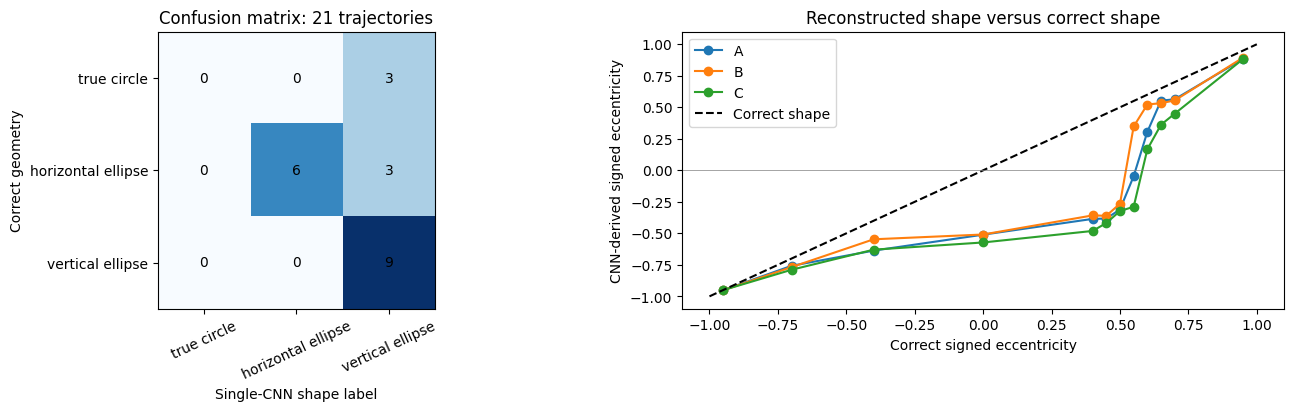

,fraction_correct
condition,
A,0.714286
B,0.714286
C,0.714286


Overall screening accuracy: 0.7142857142857143


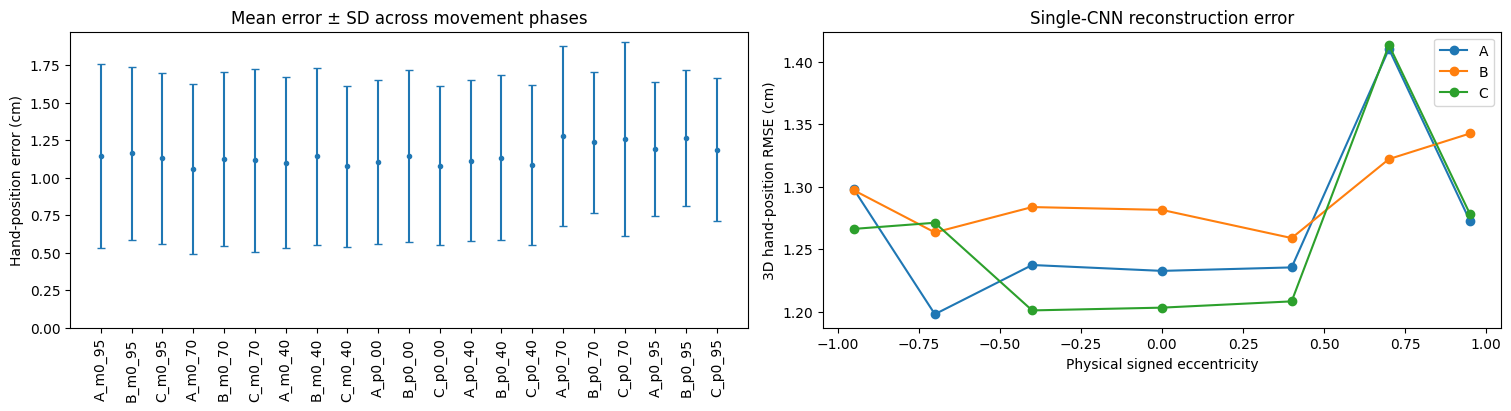

,id,mean_point_error_cm,sd_point_error_cm,rmse_3d_cm,centered_rmse_3d_cm,peak_point_error_cm
0,A_m0_95,1.145748,0.611808,1.297902,1.038416,4.630086
1,B_m0_95,1.162812,0.576643,1.297086,1.024672,4.384388
2,C_m0_95,1.131337,0.570382,1.266132,1.008366,3.907995
3,A_m0_70,1.057426,0.564721,1.197887,0.966175,3.976304
4,B_m0_70,1.122711,0.581138,1.263309,1.034754,4.232455
5,C_m0_70,1.116052,0.610328,1.271058,1.019347,4.344082
6,A_m0_40,1.098839,0.570517,1.237242,0.981516,4.125335
7,B_m0_40,1.142123,0.587803,1.283610,1.063818,3.701356
8,C_m0_40,1.074963,0.537202,1.200920,0.937546,3.573022
9,A_p0_00,1.105673,0.546490,1.232547,0.973609,3.622446


In [4]:
matrix=pd.crosstab(predictions.correct,predictions.predicted).reindex(index=CLASSES,columns=CLASSES,fill_value=0)
fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
axes[0].imshow(matrix,cmap='Blues');axes[0].set(xticks=range(3),yticks=range(3),xticklabels=CLASSES,yticklabels=CLASSES,xlabel='Single-CNN shape label',ylabel='Correct geometry',title='Confusion matrix: 21 trajectories');axes[0].tick_params(axis='x',rotation=25)
for i in range(3):
    for j in range(3):axes[0].text(j,i,str(matrix.iloc[i,j]),ha='center',va='center')
for condition,g in pse_predictions.groupby('condition'):
    g=g.sort_values('e');axes[1].plot(g.e,g.predicted_e,'o-',label=condition)
axes[1].plot([-1,1],[-1,1],'k--',label='Correct shape');axes[1].axhline(0,c='gray',lw=.5)
axes[1].set(xlabel='Correct signed eccentricity',ylabel='CNN-derived signed eccentricity',title='Reconstructed shape versus correct shape');axes[1].legend();plt.show()
accuracy=predictions.assign(is_correct=predictions.correct==predictions.predicted).groupby('condition').is_correct.mean()
display(accuracy.rename('fraction_correct').to_frame())
print('Overall screening accuracy:',(predictions.correct==predictions.predicted).mean())

errors=pd.read_csv(OUT/'trajectory_errors.csv')
fig,axes=plt.subplots(1,2,figsize=(15,4),layout='constrained')
x=np.arange(len(errors))
axes[0].errorbar(x,errors.mean_point_error_cm,yerr=errors.sd_point_error_cm,fmt='o',capsize=3,ms=3)
axes[0].set(xticks=x,xticklabels=errors.id,ylabel='Hand-position error (cm)',title='Mean error ± SD across movement phases')
axes[0].tick_params(axis='x',rotation=90);axes[0].set_ylim(bottom=0)
for condition,g in errors.groupby('condition'):
    axes[1].plot(g.e,g.rmse_3d_cm,'o-',label=condition)
axes[1].set(xlabel='Physical signed eccentricity',ylabel='3D hand-position RMSE (cm)',title='Single-CNN reconstruction error');axes[1].legend();plt.show()
display(errors[['id','mean_point_error_cm','sd_point_error_cm','rmse_3d_cm','centered_rmse_3d_cm','peak_point_error_cm']])


## 5. Single CNN versus humans, with defined uncertainty bars

The human points are the mean of the 20 participant PSEs in Table 1. **Human bars are 95% t confidence intervals of the mean**, calculated from the individual participant means in `notebooks/data/viviani_table1_participant_pses.csv`. The table's pooled inversion SD is not substituted for between-participant SD. For B−A and C−A, confidence intervals use paired differences within the same participants.

The CNN is deterministic and we have one checkpoint, so no statistical trial-to-trial confidence interval is available. **Red model bars show the interval between tested eccentricities that brackets the observed zero crossing.** They describe grid resolution, not population or prediction uncertainty. The interpolated point and bracket are both reported. Human CIs and model brackets are different quantities and should not be interpreted as equivalent error bars.

The human task was a flat/tall choice. Our model PSE is a proxy derived from equal decoded horizontal and vertical extents, not a fitted human-choice function. Human JNDs are reference values; their uncertainty cannot be recovered from the available PSE means. The stimuli remain smaller/slower, the arm posture differs, and the chest reference is approximate, so this is an exploratory comparison.

**Refined model brackets:** 15 extra trajectories use eccentricities .45, .50, .55, .60 and .65 in each velocity condition, around the initial observed crossing interval [.4, .7]. They use the identical posture, spindle coefficients and checkpoint. PSE estimates and brackets use these samples as well as the initial grid. This is numerical refinement, not training or fitting to human responses.


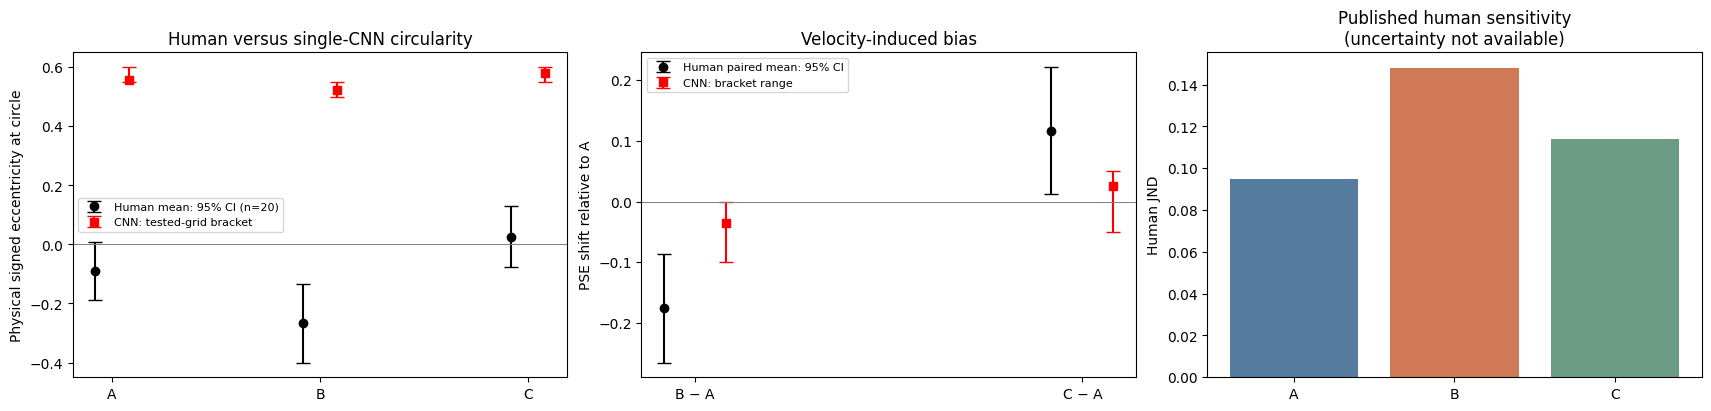

,condition,human_pse,human_sd,human_ci95_low,human_ci95_high,human_n,cnn_pse,cnn_bracket_low,cnn_bracket_high,cnn_minus_human
0,A,-0.09095,0.210926,-0.189667,0.007767,20,0.556641,0.55,0.60,0.647591
1,B,-0.26695,0.284247,-0.399982,-0.133918,20,0.521617,0.50,0.55,0.788567
2,C,0.02605,0.221113,-0.077434,0.129534,20,0.581717,0.55,0.60,0.555667


,contrast,human_mean_shift,human_ci95_low,human_ci95_high,human_n,cnn_shift,cnn_bracket_low,cnn_bracket_high
0,B-A,-0.176,-0.265442,-0.086558,20,-0.035025,-0.10,0.00
1,C-A,0.117,0.012502,0.221498,20,0.025075,-0.05,0.05


Human bars: confidence intervals over 20 participants. CNN bars: eccentricity-grid brackets, not confidence intervals.
Single-CNN reconstruction RMSE: see Section 4. Models used: 1


In [5]:
comparison=pd.read_csv(OUT/'human_model_comparison.csv')
shifts=pd.read_csv(OUT/'pse_shift_comparison.csv')
fig,axes=plt.subplots(1,3,figsize=(17,4),layout='constrained');x=np.arange(3)
human_yerr=np.vstack([comparison.human_pse-comparison.human_ci95_low,comparison.human_ci95_high-comparison.human_pse])
axes[0].errorbar(x-.08,comparison.human_pse,yerr=human_yerr,fmt='ko',capsize=5,label='Human mean: 95% CI (n=20)')
model_yerr=np.vstack([comparison.cnn_pse-comparison.cnn_bracket_low,comparison.cnn_bracket_high-comparison.cnn_pse])
axes[0].errorbar(x+.08,comparison.cnn_pse,yerr=model_yerr,fmt='rs',capsize=5,label='CNN: tested-grid bracket')
axes[0].axhline(0,c='gray',lw=.7);axes[0].set(xticks=x,xticklabels=list('ABC'),ylabel='Physical signed eccentricity at circle',title='Human versus single-CNN circularity');axes[0].legend(fontsize=8)
yerr=np.vstack([shifts.human_mean_shift-shifts.human_ci95_low,shifts.human_ci95_high-shifts.human_mean_shift])
axes[1].errorbar(np.arange(2)-.08,shifts.human_mean_shift,yerr=yerr,fmt='ko',capsize=5,label='Human paired mean: 95% CI')
yerr=np.vstack([shifts.cnn_shift-shifts.cnn_bracket_low,shifts.cnn_bracket_high-shifts.cnn_shift])
axes[1].errorbar(np.arange(2)+.08,shifts.cnn_shift,yerr=yerr,fmt='rs',capsize=5,label='CNN: bracket range')
axes[1].axhline(0,c='gray',lw=.7);axes[1].set(xticks=[0,1],xticklabels=['B − A','C − A'],ylabel='PSE shift relative to A',title='Velocity-induced bias');axes[1].legend(fontsize=8)
axes[2].bar(x,[.095,.148,.114],color=['#557b9e','#cf7957','#6b9b82']);axes[2].set(xticks=x,xticklabels=list('ABC'),ylabel='Human JND',title='Published human sensitivity\n(uncertainty not available)');plt.show()
display(comparison);display(shifts)
print('Human bars: confidence intervals over 20 participants. CNN bars: eccentricity-grid brackets, not confidence intervals.')
print('Single-CNN reconstruction RMSE: see Section 4. Models used:',provenance['n_models'])


**Reproducibility.** Outputs and checks are in `outputs/viviani_aligned/`. The active experiment is `experiments/viviani_aligned.yaml`; original and large-path diagnostic outputs are retained separately. Checkpoint and configuration hashes are recorded in `single_model_provenance.json`. To regenerate, set both run flags to `True` and run cells in order. Existing notebooks `run_pipeline.ipynb` and `mujoco_spindle_pipeline.ipynb` are not overwritten by this notebook.

**Limits.** Passing marker, fibre-length and velocity screens removes the specific failures seen previously; it does not prove that synthetic firing rates equal human afferent recordings. The scale, speed, posture, spindle approximation and fixed geometric readout all limit conclusions about the human illusion. No human data were used to train or tune the CNN.

Human CI assumptions: participant PSE means are treated as independent observations; t intervals are descriptive uncertainty in the cohort mean. The paired contrast is computed from Table 1 means rather than the paper’s Figure 3 pooled-median method. No human responses were used to select the posture, modify weights, or tune CNN predictions.

The focused 15-trajectory refinement uses `experiments/viviani_aligned_refine.yaml` and `outputs/viviani_aligned_refine/`. Both run flags regenerate that set as well. Its checkpoint checksum is checked against the main run before combining PSE data; the 21-case performance statistic remains separate.


## 6. What does the CNN predict for circles at different positions?

This adds a position experiment using the **same single CNN**. All 100 inputs are true circles of perimeter 32 cm (radius 5.09 cm), period 2.5 s, and counterclockwise direction. Each circle lies in a **vertical plane** at its grid location; right and forward specify its center, and center height is held at the reference shoulder height. Thus the image's top-down grid locates the circles; it does not turn the circles into horizontal movements.

**Grid approximation:** the original numeric grid was unavailable. `notebooks/data/circle_position_grid.csv` defines a uniform 20 × 5 approximation inferred from the image's achieved-hand arrowhead region: right −5.3 to +5.9 cm and forward 30.8 to 36.1 cm, relative to C7. The shared requested hand start is approximately (right .15, forward 33.48) cm at the same height. These are model-test coordinates, not the original numeric positions from the supplied image.

**Same starting place:** every trial begins with a .5 s hold at that one hand position, then a 1 s minimum-jerk reach to the selected circle's participant-left edge and a .5 s settling hold. The arm traces three full circles; only the **third complete cycle** is classified. A further .25 s of circular movement buffers the analyzed cycle from sequence-end filtering. The approach reach is excluded from circle-shape readout. The actual achieved common start and the physical circles are checked before the CNN runs.

**Readout:** the colored map keeps the earlier circle/horizontal/vertical extent rule (±5% around equal extents). The additional fitted major/minor axis ratio and angle detect tilted distortions that equal horizontal/vertical extents can conceal. A fitted ratio of 1 is round. Fits are descriptive summaries of the decoded path, not another neural model. The 100-panel plot shows actual and decoded vertical paths, centered separately so shape changes are distinct from position bias. The center-arrow plot separately shows errors in circle location.

**Interpretation:** decoded loops can be irregular rather than clean ellipses. The table includes ellipse-fit residuals; large residuals make a fitted ratio/angle only a rough summary. Equal horizontal/vertical extents do not establish roundness, and fitted angles are unstable for nearly round paths. The raw overlays are retained without smoothing to make these limitations visible.

**How to read the center map:** this is a view from above. Right increases to the right and forward increases upward, measured from the neck reference (C7). Each purple dot is the CNN-predicted circle center; its arrow points to the actual center of the circle traced by the simulated hand. The coral ring and cross mark the shared hand starting point. A left-pointing arrow means the CNN placed the center too far right. Each circle itself lies in the vertical X–Z plane, at a fixed forward distance. The body inset is a sketch. The separate vertical shape panels are centered individually to compare shapes.


Positions: 100 | CNN checkpoints: 1
Shared achieved-start difference: 0.0 cm


,n_positions
predicted,
circle,40
horizontal ellipse,22
vertical ellipse,38


Circle labels use the earlier extent rule. Rotation-aware fit ratios range from 1.013 to 1.421
Mean ellipse-fit residual (cm): 1.1099155014007254
Extent-circle cases with fitted axis ratio > 1.05: 39


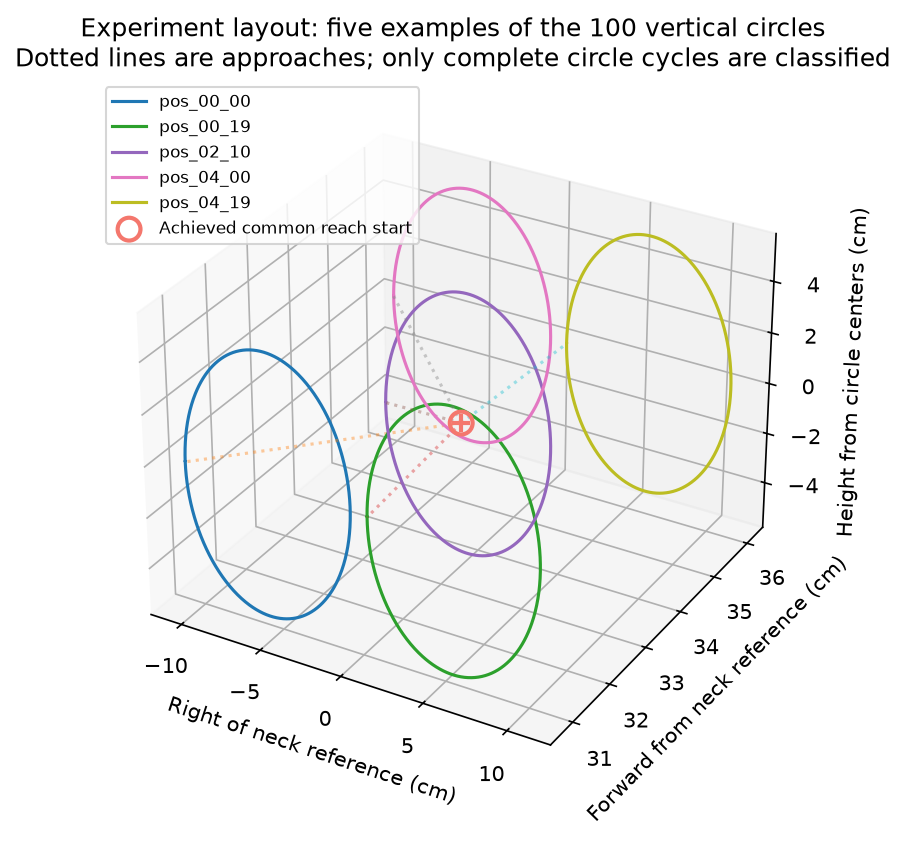

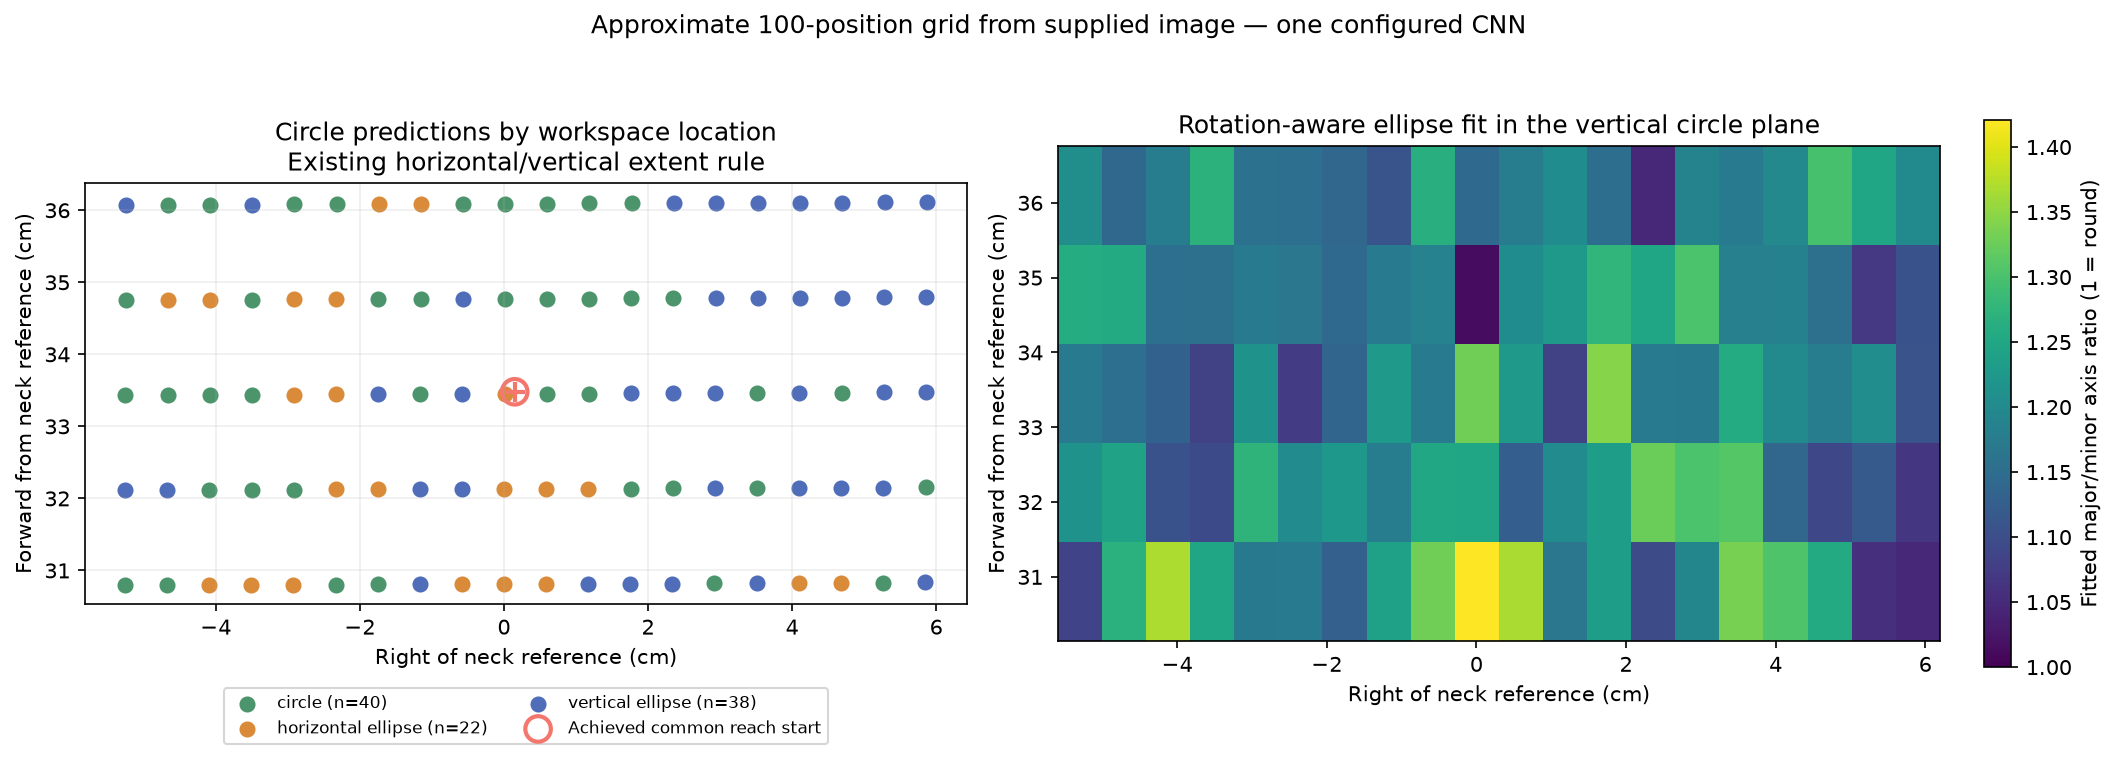

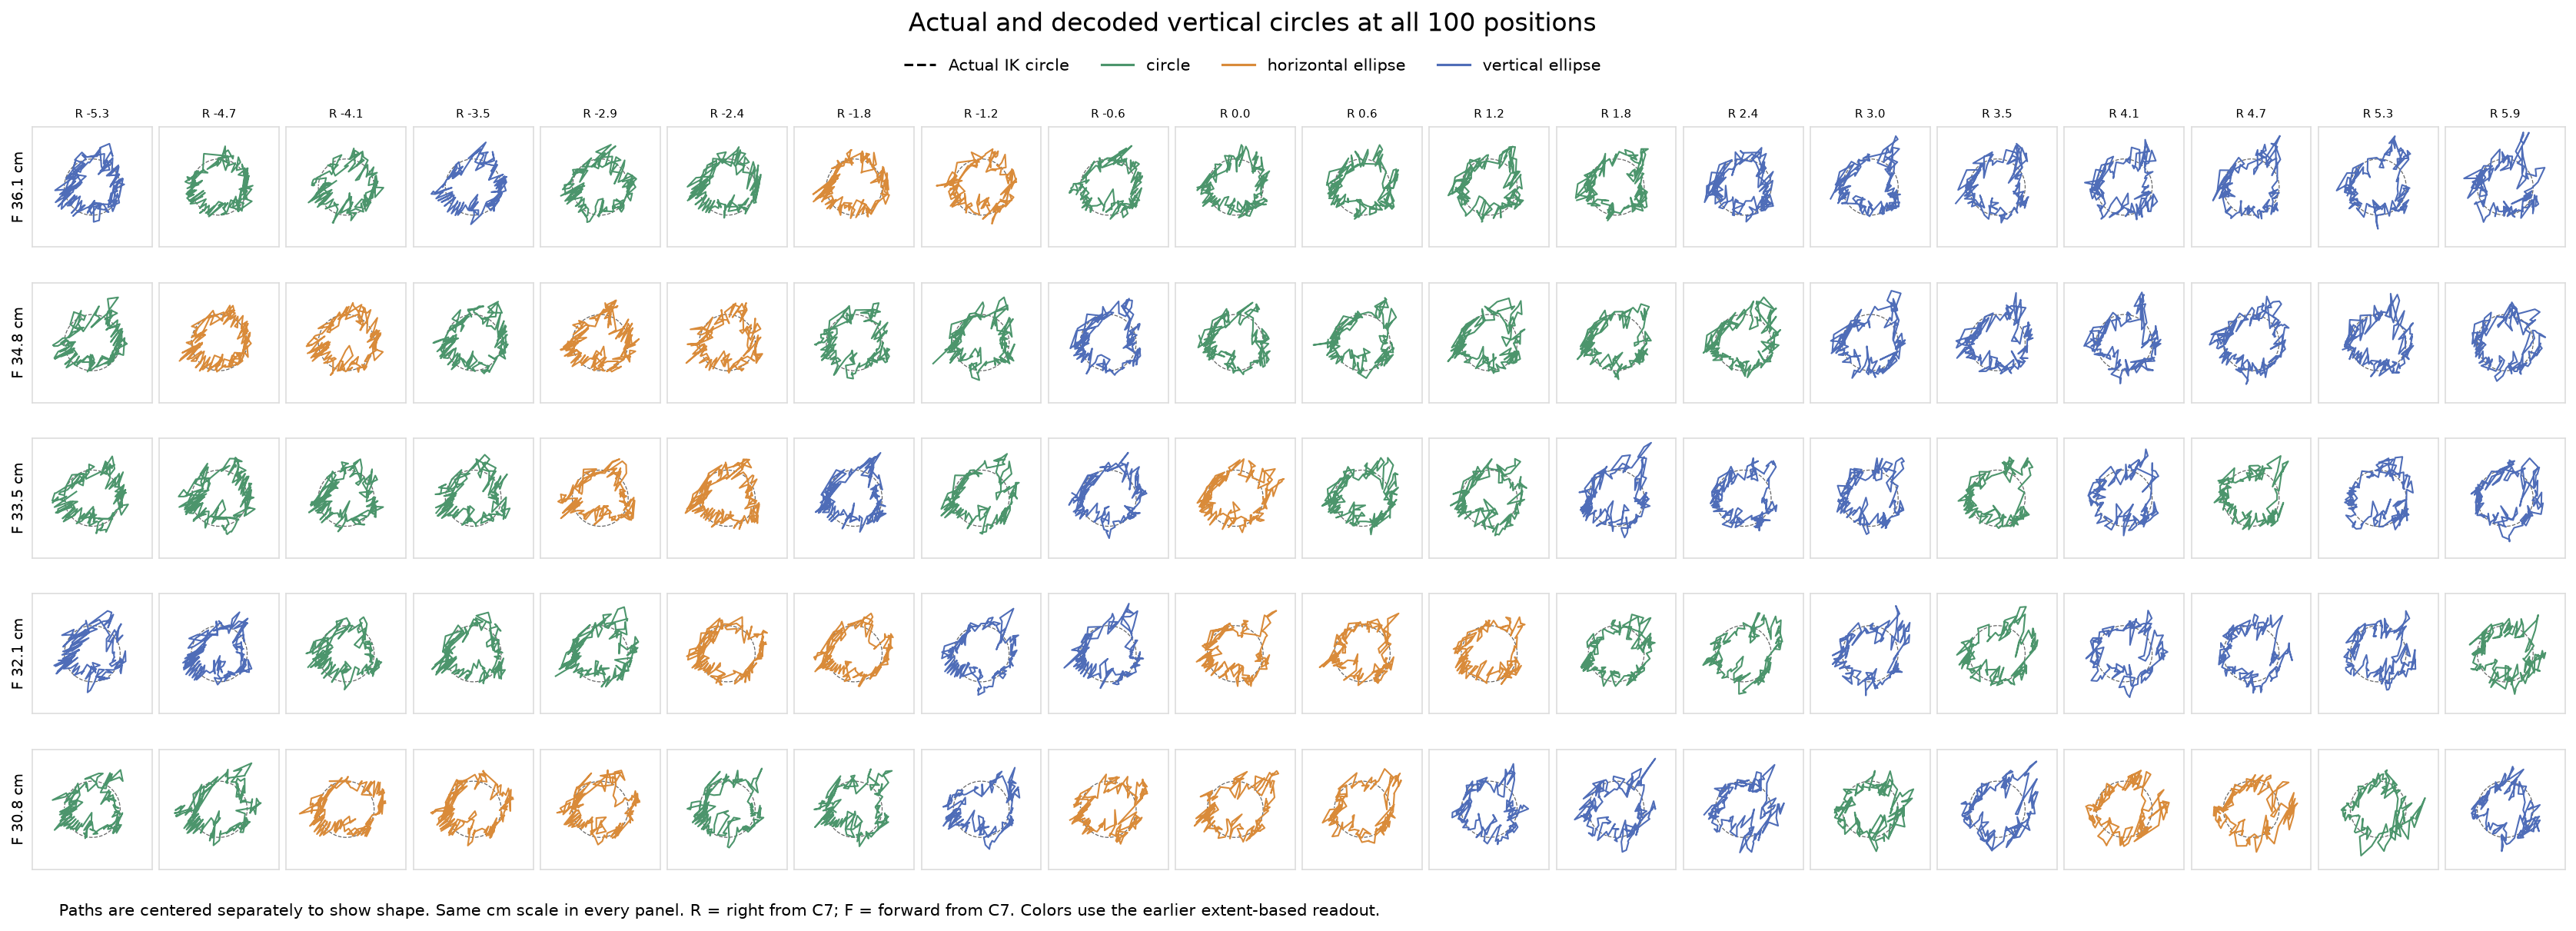

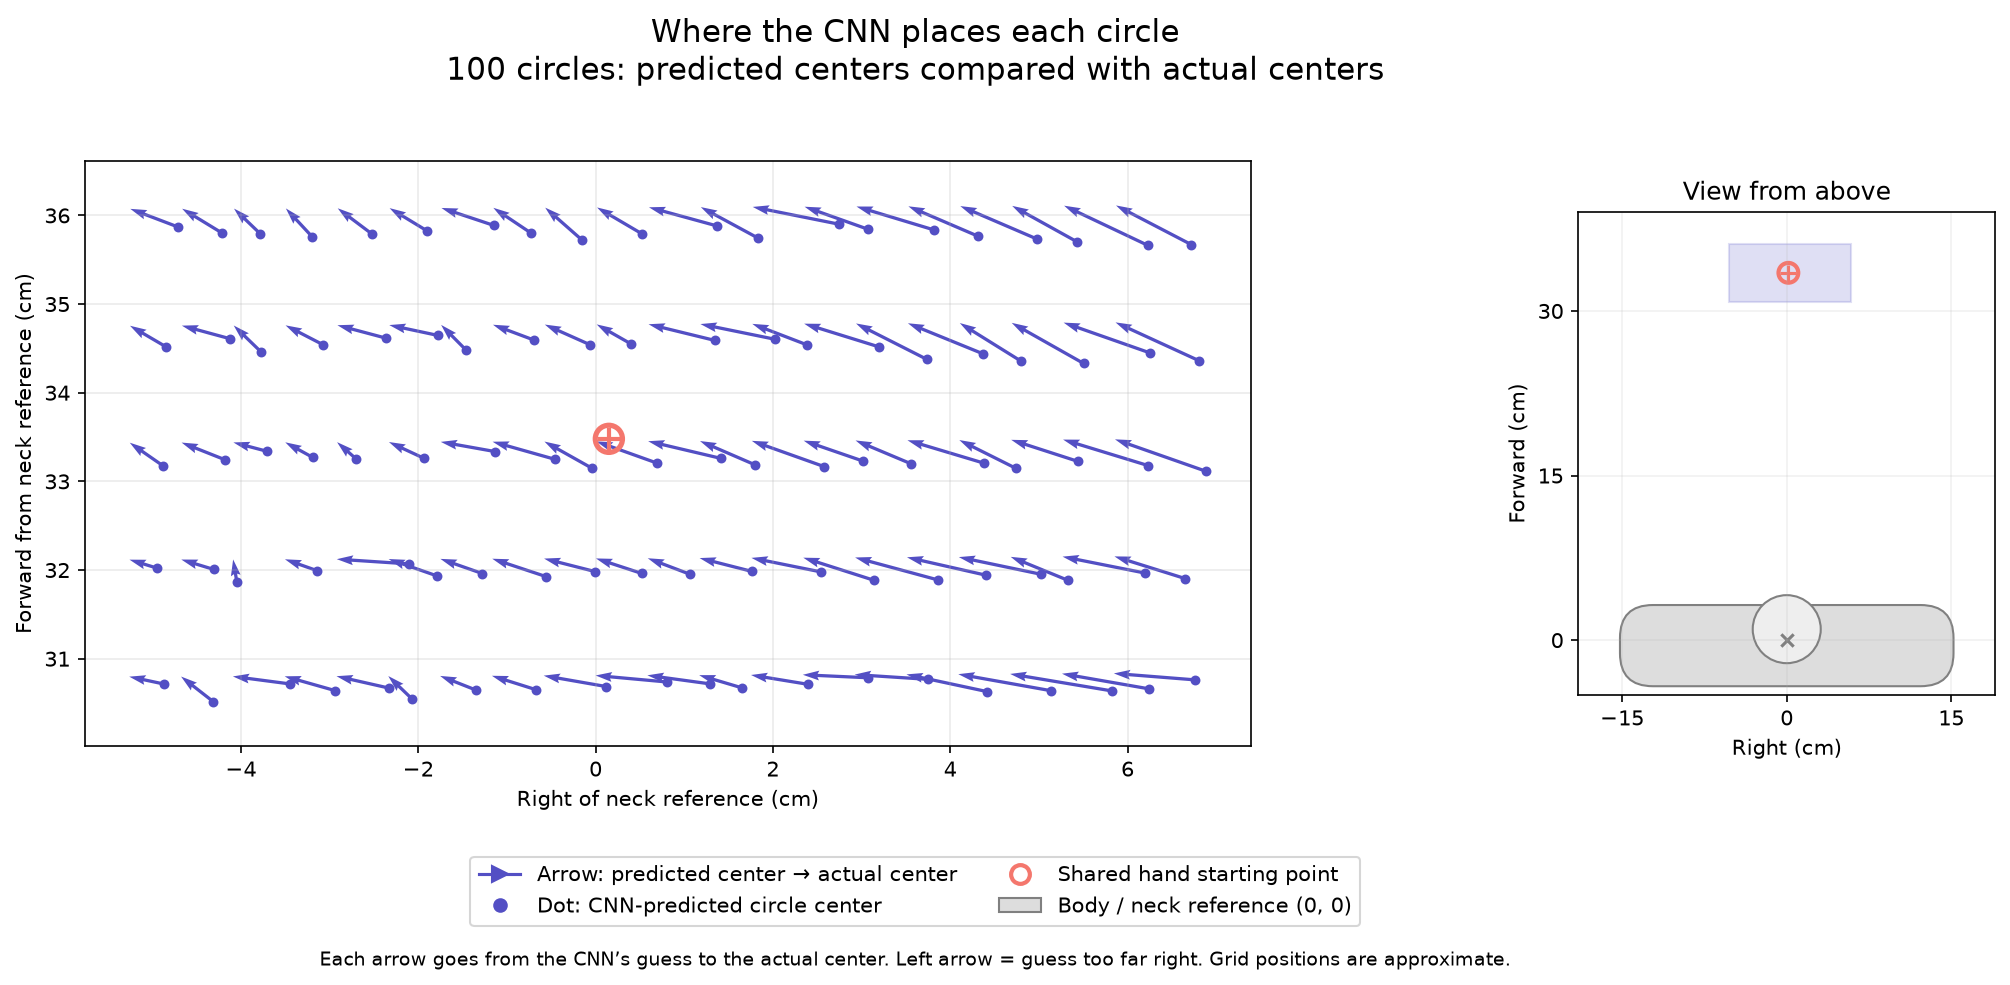

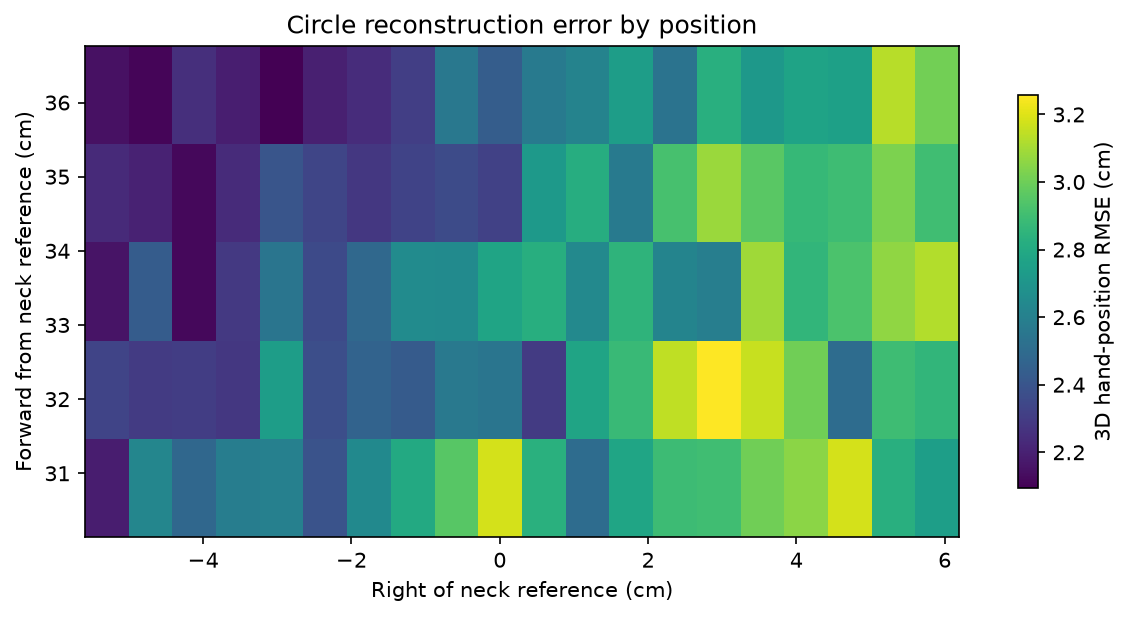

,id,right_cm,forward_cm,predicted,actual_extent_ratio,extent_ratio,actual_fitted_axis_ratio,fitted_axis_ratio,fitted_angle_deg,ellipse_fit_rmse_cm,rmse_3d_cm,centroid_error_cm,joint_out_of_bounds_fraction
0,pos_00_00,-5.300000,30.8,circle,0.993585,1.028732,1.006705,1.084625,51.011442,1.160425,2.185234,1.062700,0.0
1,pos_00_01,-4.710526,30.8,circle,0.993587,1.049788,1.006783,1.268273,22.612779,1.287805,2.626024,1.145600,0.0
2,pos_00_02,-4.121053,30.8,horizontal ellipse,0.993112,1.441040,1.006917,1.368764,11.720632,0.982767,2.481476,1.329971,0.0
3,pos_00_03,-3.531579,30.8,horizontal ellipse,0.993249,1.098684,1.006922,1.247545,24.496562,1.100293,2.585699,1.440423,0.0
4,pos_00_04,-2.942105,30.8,horizontal ellipse,0.992853,1.108440,1.007027,1.169369,21.044343,1.122899,2.601456,1.477065,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,pos_04_15,3.542105,36.1,vertical ellipse,0.994630,0.918993,1.005764,1.175722,59.661244,1.118103,2.714602,1.941473,0.0
96,pos_04_16,4.131579,36.1,vertical ellipse,0.994638,0.907866,1.005790,1.197842,56.693992,1.137785,2.769050,1.998915,0.0
97,pos_04_17,4.721053,36.1,vertical ellipse,0.994233,0.814072,1.005809,1.298539,52.722420,1.068164,2.755659,1.907930,0.0
98,pos_04_18,5.310526,36.1,vertical ellipse,0.994593,0.795256,1.005814,1.248337,54.307550,1.148203,3.130333,2.288504,0.0


Detailed CSV: /Users/macbookair2026/Documents/motor-metamers/MotorMetamersuPNC/outputs/circle_position_grid/circle_position_predictions.csv


In [6]:
# Run this section independently, or after Sections 1–5.
from pathlib import Path
import json,hashlib,subprocess,os
import numpy as np
import pandas as pd
import yaml
from IPython.display import display,Image
GRID_ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'run_pipeline.py').exists())
GRID_CONFIG_PATH=GRID_ROOT/'experiments/circle_positions.yaml'
GRID_CONFIG=yaml.safe_load(GRID_CONFIG_PATH.read_text())
GRID_OUT=GRID_ROOT/'outputs'/GRID_CONFIG['experiment']
RUN_POSITION_GRID=False  # True recalculates workspace trials and calls the single configured CNN.
if RUN_POSITION_GRID:
    with (GRID_ROOT/'outputs/circle_position_batch.log').open('w') as log:
        subprocess.run([str(GRID_ROOT/'.venv-opensim/bin/python'),'process/run_circle_position_batch.py','--config',str(GRID_CONFIG_PATH),'--workers','3'],cwd=GRID_ROOT,stdout=log,stderr=subprocess.STDOUT,check=True)
grid_provenance=json.loads((GRID_OUT/'single_model_provenance.json').read_text())
grid_signature=hashlib.sha256(json.dumps(GRID_CONFIG,sort_keys=True).encode()).hexdigest()
assert grid_provenance['grid_csv_sha256']==hashlib.sha256((GRID_ROOT/GRID_CONFIG['path']['circle_positions']['grid_csv']).read_bytes()).hexdigest()
assert grid_provenance['n_models']==1 and grid_provenance['config_signature']==grid_signature
assert grid_provenance['checkpoint_sha256']==hashlib.sha256((GRID_ROOT/GRID_CONFIG['proprioception']['model_path']/'model.ckpt').read_bytes()).hexdigest()
original_config=yaml.safe_load((GRID_ROOT/'experiments/viviani_aligned.yaml').read_text())
assert GRID_CONFIG['proprioception']==original_config['proprioception'], 'The grid must use the same checkpoint and spindle coefficients.'
grid_quality=pd.read_csv(GRID_OUT/'circle_position_quality.csv')
grid_results=pd.read_csv(GRID_OUT/'circle_position_predictions.csv')
grid_start=json.loads((GRID_OUT/'common_start_check.json').read_text())
assert len(grid_results)==100 and grid_quality.passed.all()
assert grid_start['max_achieved_start_difference_cm']<.05
with (GRID_OUT/'plots.log').open('w') as log:
    subprocess.run([str(GRID_ROOT/'.venv-mujoco/bin/python'),'process/plot_circle_positions.py','--output',str(GRID_OUT)],cwd=GRID_ROOT,env=dict(os.environ,MPLBACKEND='Agg',MPLCONFIGDIR=str(GRID_OUT/'.matplotlib')),stdout=log,stderr=subprocess.STDOUT,check=True)
grid_summary=json.loads((GRID_OUT/'circle_position_summary.json').read_text())
print('Positions:',grid_summary['n_positions'],'| CNN checkpoints:',grid_summary['n_models'])
print('Shared achieved-start difference:',grid_start['max_achieved_start_difference_cm'],'cm')
display(grid_results.groupby('predicted').size().rename('n_positions').to_frame())
print('Circle labels use the earlier extent rule. Rotation-aware fit ratios range from',round(grid_summary['fitted_axis_ratio_min'],3),'to',round(grid_summary['fitted_axis_ratio_max'],3))
print('Mean ellipse-fit residual (cm):',grid_results.ellipse_fit_rmse_cm.mean())
print('Extent-circle cases with fitted axis ratio > 1.05:',grid_summary['extent_circle_with_fitted_axis_ratio_over_1_05'])
for name in ['circle_position_layout.png','circle_position_shape_map.png','circle_position_mosaic.png','circle_position_centroid_bias.png','circle_position_error_map.png']:
    display(Image(filename=str(GRID_OUT/'figures'/name)))
display(grid_results[['id','right_cm','forward_cm','predicted','actual_extent_ratio','extent_ratio','actual_fitted_axis_ratio','fitted_axis_ratio','fitted_angle_deg','ellipse_fit_rmse_cm','rmse_3d_cm','centroid_error_cm','joint_out_of_bounds_fraction']])
print('Detailed CSV:',GRID_OUT/'circle_position_predictions.csv')
